In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals

sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/OptimizeSignalStudies/OptimizeSignalStudies.coffea"

sig_histo = util.load(f_sig) [0]
# sig_histo

In [3]:
selected_cut = "cut2"


m1=10, delta=0.2, ctau=100: denominator = 219982
m1=20, delta=0.2, ctau=100: denominator = 285981
m1=30, delta=0.2, ctau=100: denominator = 307204
m1=40, delta=0.2, ctau=100: denominator = 303385
m1=50, delta=0.2, ctau=100: denominator = 275148
m1=60, delta=0.1, ctau=100: denominator = 387820
m1=60, delta=0.2, ctau=100: denominator = 223856
m1=70, delta=0.1, ctau=100: denominator = 378359
m1=70, delta=0.2, ctau=100: denominator = 139727
m1=80, delta=0.1, ctau=100: denominator = 252285
m1=80, delta=0.2, ctau=100: denominator = 163058
m1=90, delta=0.1, ctau=100: denominator = 294517
m1=90, delta=0.2, ctau=100: denominator = 103316
m1=100, delta=0.1, ctau=100: denominator = 249464
m1=100, delta=0.2, ctau=100: denominator = 110862

Cut: cut2
Number of samples: 15
TOTAL denominator = 3.69496e+06


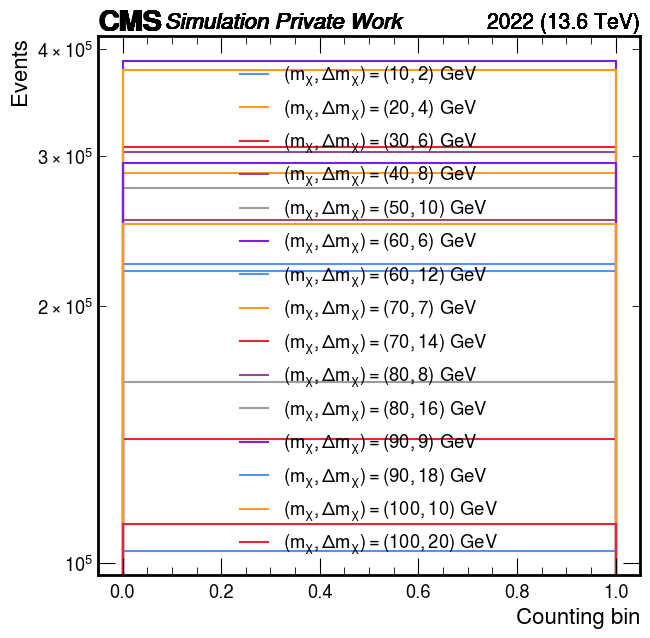

In [4]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'eff_den',
    'cut': selected_cut,
    'year': 2022
}
style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': "Counting bin",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
}

samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
 
}



den_counts = {}
total_den = 0.0
den_cut = plot_dict["cut"]

for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            key = (m1, delta, ctau)
            if key in den_counts:
                raise ValueError(f"Sample listed more than once: {key}")
            counts = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            den = float(np.asarray(counts, dtype=float).sum())
            den_counts[key] = den
            total_den += den
            print(f"m1={m1}, delta={delta}, ctau={ctau}: denominator = {den:g}")

print(f"\nCut: {den_cut}")
print(f"Number of samples: {len(den_counts)}")
print(f"TOTAL denominator = {total_den:g}")
plt.show()


m1=10, delta=0.2, ctau=100: numerator = 14533
m1=20, delta=0.2, ctau=100: numerator = 22610
m1=30, delta=0.2, ctau=100: numerator = 28607
m1=40, delta=0.2, ctau=100: numerator = 30041
m1=50, delta=0.2, ctau=100: numerator = 28233
m1=60, delta=0.1, ctau=100: numerator = 33684
m1=60, delta=0.2, ctau=100: numerator = 23531
m1=70, delta=0.1, ctau=100: numerator = 35857
m1=70, delta=0.2, ctau=100: numerator = 15063
m1=80, delta=0.1, ctau=100: numerator = 25451
m1=80, delta=0.2, ctau=100: numerator = 17570
m1=90, delta=0.1, ctau=100: numerator = 31537
m1=90, delta=0.2, ctau=100: numerator = 11208
m1=100, delta=0.1, ctau=100: numerator = 27749
m1=100, delta=0.2, ctau=100: numerator = 11776

Cut: cut2
Number of samples: 15
TOTAL numerator = 357450


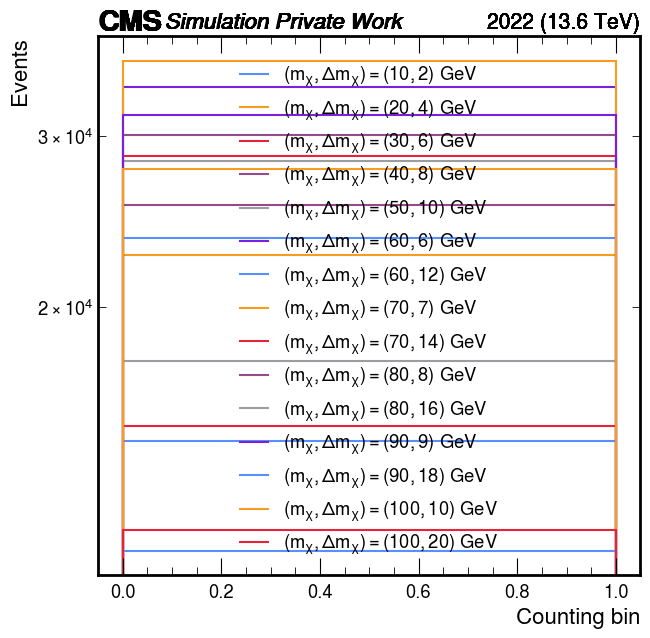

In [5]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'eff_num',
    'cut': selected_cut,
    'year': 2022
}
style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': "Counting bin",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
}



if plot_dict["cut"] != den_cut:
    raise ValueError("Cuts differ. Use the same cut in both counting cells and rerun them.")

num_counts = {}
total_num = 0.0
num_cut = plot_dict["cut"]

# Reuse exactly the samples selected in the denominator cell.
for key in den_counts:
    m1, delta, ctau = key
    counts = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
    num = float(np.asarray(counts, dtype=float).sum())
    num_counts[key] = num
    total_num += num
    print(f"m1={m1}, delta={delta}, ctau={ctau}: numerator = {num:g}")

print(f"\nCut: {num_cut}")
print(f"Number of samples: {len(num_counts)}")
print(f"TOTAL numerator = {total_num:g}")
plt.show()